# 01 Exploratory data analysis

Train split only. Charts are saved to `figures/`.

## Setup

In [1]:
# Setup: in Colab, clone the repo and install packages. Locally, use the checkout.
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import userdata
    token = userdata.get('GH_TOKEN')
    if not os.path.exists('/content/credit-card-fraud-detection'):
        !git clone -q https://{token}@github.com/VanshSharmaPES/credit-card-fraud-detection.git /content/credit-card-fraud-detection
    %cd /content/credit-card-fraud-detection
    !pip install -q -r requirements/base.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
!{sys.executable} src/data.py
sys.path.append('src')

Raw rows: 284807, raw frauds: 492
Duplicates dropped: 1081
Rows after cleaning: 283726, frauds: 473
train rows:  170235  frauds:  284  fraud share: 0.1668%
val   rows:   56745  frauds:   94  fraud share: 0.1657%
test  rows:   56746  frauds:   95  fraud share: 0.1674%
Class weight (train normal / train fraud): 169951 / 284 = 598.4190


In [2]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import RAW_PATH, PROCESSED_DIR, FEATURES

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

# Colours: one per class, and a blue-grey-red scale for correlations
NORMAL, FRAUD = '#2a78d6', '#eb6834'
NEG, MID, POS = '#2a78d6', '#f0efec', '#e34948'
CLASS_NAMES = {0: 'Normal', 1: 'Fraud'}
CLASS_COLOURS = {0: NORMAL, 1: FRAUD}

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'legend.frameon': False,
})
pd.set_option('display.float_format', '{:,.4f}'.format)


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches='tight')
    print('Saved', FIG_DIR / name)

## 1. Basic checks on the raw file

In [3]:
raw = pd.read_csv(RAW_PATH)
dupes = raw.duplicated()

print('Shape:', raw.shape)
print('\nColumn types:')
print(raw.dtypes.value_counts().to_string())
print('\nMissing values (all columns):', int(raw.isna().sum().sum()))
print('Duplicate rows:', int(dupes.sum()))
print('Frauds among duplicate rows:', int(raw.loc[dupes, 'Class'].sum()))
print('Fraud share in raw file:', f"{raw['Class'].mean():.4%}")
raw.head()

Shape: (284807, 31)

Column types:
float64    30
int64       1

Missing values (all columns): 0
Duplicate rows: 1081
Frauds among duplicate rows: 19
Fraud share in raw file: 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## Train split with readable values

In [4]:
# The processed train split is scaled, so charts would be unreadable.
# Instead take the raw rows whose row_id is in the train split.
# row_id is the original row number, which is also raw's index.
train = pd.read_csv(PROCESSED_DIR / 'train.csv')
eda = raw.loc[train['row_id']].copy()
eda['Hour'] = ((eda['Time'] // 3600) % 24).astype(int)
eda['Label'] = eda['Class'].map(CLASS_NAMES)

assert len(eda) == len(train)
assert (eda['Class'].values == train['Class'].values).all()
print('Train rows:', len(eda), '| train frauds:', int(eda['Class'].sum()))

Train rows: 170235 | train frauds: 284


## 2. Class balance

Saved figures/eda_class_balance.png


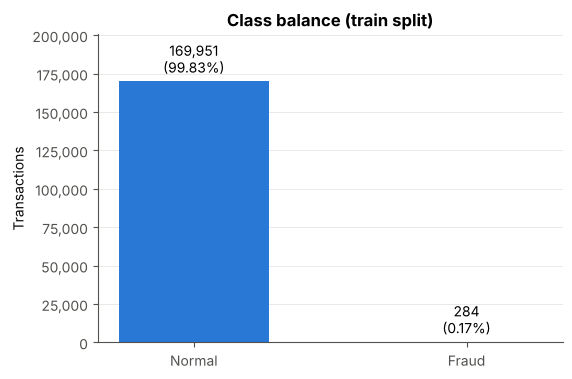

         count  share
Class                
Normal  169951 0.9983
Fraud      284 0.0017


In [5]:
counts = eda['Class'].value_counts().sort_index()
shares = counts / counts.sum()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([CLASS_NAMES[c] for c in counts.index], counts.values,
              color=[CLASS_COLOURS[c] for c in counts.index], width=0.55)
for bar, n, s in zip(bars, counts.values, shares.values):
    ax.annotate(f'{n:,}\n({s:.2%})', (bar.get_x() + bar.get_width() / 2, n),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel('Transactions')
ax.set_title('Class balance (train split)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='x', visible=False)
save(fig, 'eda_class_balance.png')
plt.show()
print(pd.DataFrame({'count': counts, 'share': shares}).rename(index=CLASS_NAMES))

## 3. Amount by class

Zero-amount transactions by class:
Label
Fraud       12
Normal    1056


Saved figures/eda_amount_by_class.png


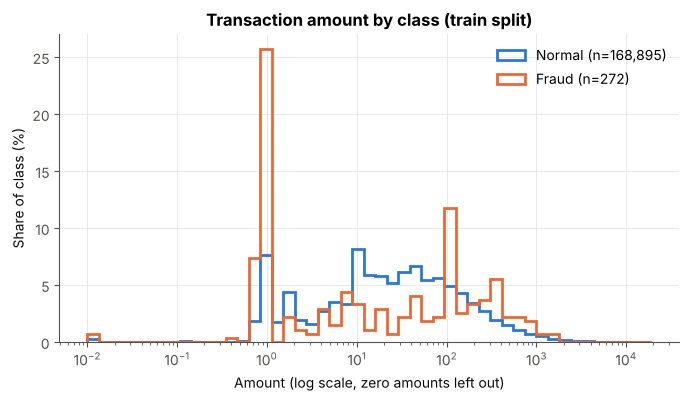

,count,mean,std,min,25%,50%,75%,95%,max
Label,,,,,,,,,
Fraud,284.0000,111.4179,219.0493,0.0000,1.0000,9.1700,104.4950,565.1080,"1,504.9300"
Normal,"169,951.0000",88.2663,243.9547,0.0000,5.6700,22.0000,77.5050,363.7300,"18,910.0000"


In [6]:
print('Zero-amount transactions by class:')
print(eda[eda['Amount'] == 0].groupby('Label').size().to_string())

# A log axis cannot show 0, so zero amounts are left out of the chart (counted above).
# Each class's bars add up to 100% of its non-zero transactions.
positive = eda[eda['Amount'] > 0]
bins = np.logspace(np.log10(positive['Amount'].min()), np.log10(positive['Amount'].max()), 50)
fig, ax = plt.subplots(figsize=(8, 4))
for c in (0, 1):
    a = positive.loc[positive['Class'] == c, 'Amount']
    ax.hist(a, bins=bins, weights=np.full(len(a), 100 / len(a)), histtype='step', linewidth=2,
            color=CLASS_COLOURS[c], label=f'{CLASS_NAMES[c]} (n={len(a):,})')
ax.set_xscale('log')
ax.set_xlabel('Amount (log scale, zero amounts left out)')
ax.set_ylabel('Share of class (%)')
ax.set_title('Transaction amount by class (train split)')
ax.legend()
save(fig, 'eda_amount_by_class.png')
plt.show()

eda.groupby('Label')['Amount'].describe(percentiles=[0.25, 0.5, 0.75, 0.95])

## 4. Hour pattern

Saved figures/eda_hour_pattern.png


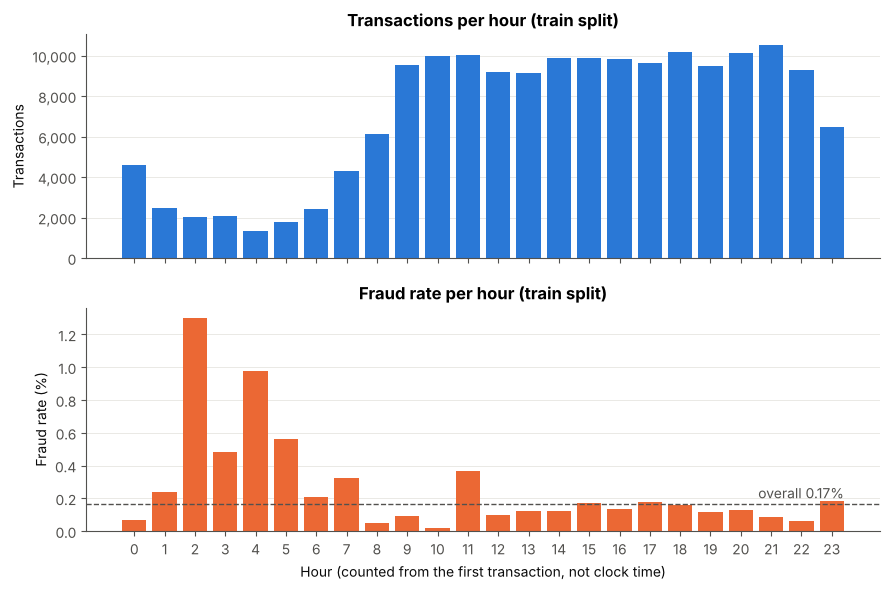

,count,frauds,fraud_rate_%
Hour,,,
0,4574,3,0.0656
1,2484,6,0.2415
2,2002,26,1.2987
3,2080,10,0.4808
4,1329,13,0.9782
5,1774,10,0.5637
6,2437,5,0.2052
7,4309,14,0.3249
8,6129,3,0.0489


In [7]:
by_hour = eda.groupby('Hour')['Class'].agg(count='size', frauds='sum')
by_hour['fraud_rate'] = by_hour['frauds'] / by_hour['count']
overall = eda['Class'].mean()

# Two panels with a shared hour axis (not one chart with two y-axes)
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
top.bar(by_hour.index, by_hour['count'], color=NORMAL, width=0.8)
top.set_ylabel('Transactions')
top.set_title('Transactions per hour (train split)')
top.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))

bottom.bar(by_hour.index, by_hour['fraud_rate'] * 100, color=FRAUD, width=0.8)
bottom.axhline(overall * 100, color='#52514e', linestyle='--', linewidth=1)
bottom.annotate(f'overall {overall:.2%}', (23.4, overall * 100), xytext=(0, 4),
                textcoords='offset points', ha='right', color='#52514e')
bottom.set_ylabel('Fraud rate (%)')
bottom.set_title('Fraud rate per hour (train split)')
bottom.set_xlabel('Hour (counted from the first transaction, not clock time)')
bottom.set_xticks(range(24))
for ax in (top, bottom):
    ax.grid(axis='x', visible=False)
fig.tight_layout()
save(fig, 'eda_hour_pattern.png')
plt.show()

by_hour.assign(fraud_rate=by_hour['fraud_rate'] * 100).rename(columns={'fraud_rate': 'fraud_rate_%'})

## 5. Correlation of each feature with Class

Saved figures/eda_corr_with_class.png


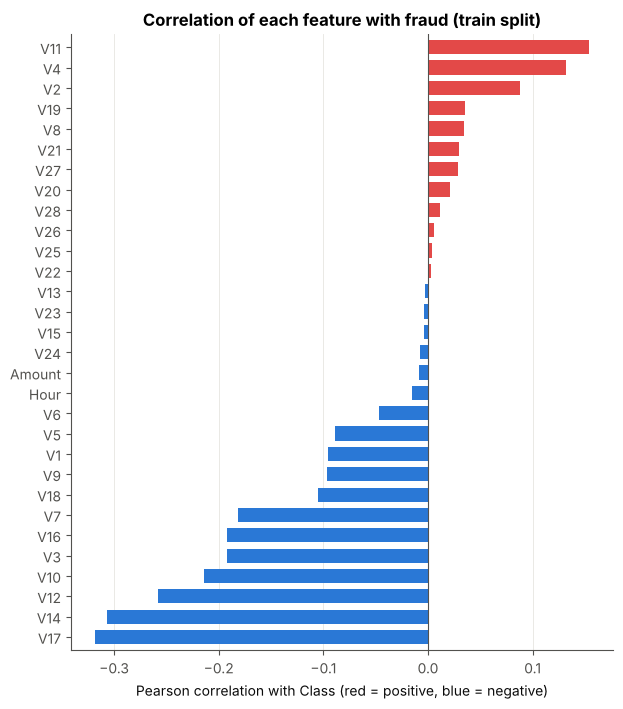

,corr,abs_corr
V17,-0.3178,0.3178
V14,-0.3066,0.3066
V12,-0.2577,0.2577
V10,-0.2145,0.2145
V3,-0.1922,0.1922
V16,-0.1916,0.1916
V7,-0.1820,0.1820
V11,0.1535,0.1535
V4,0.1321,0.1321
V18,-0.1052,0.1052


In [8]:
# Correlation with Class on the model features (train split).
# Scaling does not change correlation; Amount here is log1p(Amount).
corr = train[FEATURES].corrwith(train['Class']).sort_values()

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(corr.index, corr.values, color=[NEG if v < 0 else POS for v in corr.values], height=0.7)
ax.axvline(0, color='#52514e', linewidth=0.8)
ax.set_xlabel('Pearson correlation with Class (red = positive, blue = negative)')
ax.set_title('Correlation of each feature with fraud (train split)')
ax.grid(axis='y', visible=False)
ax.margins(y=0.01)
save(fig, 'eda_corr_with_class.png')
plt.show()

corr_table = corr.to_frame('corr').assign(abs_corr=corr.abs()).sort_values('abs_corr', ascending=False)
corr_table

## 6. Features most linked to fraud

Top features by |correlation| with Class: ['V17', 'V14', 'V12', 'V10', 'V3', 'V16']


Saved figures/eda_top_features.png


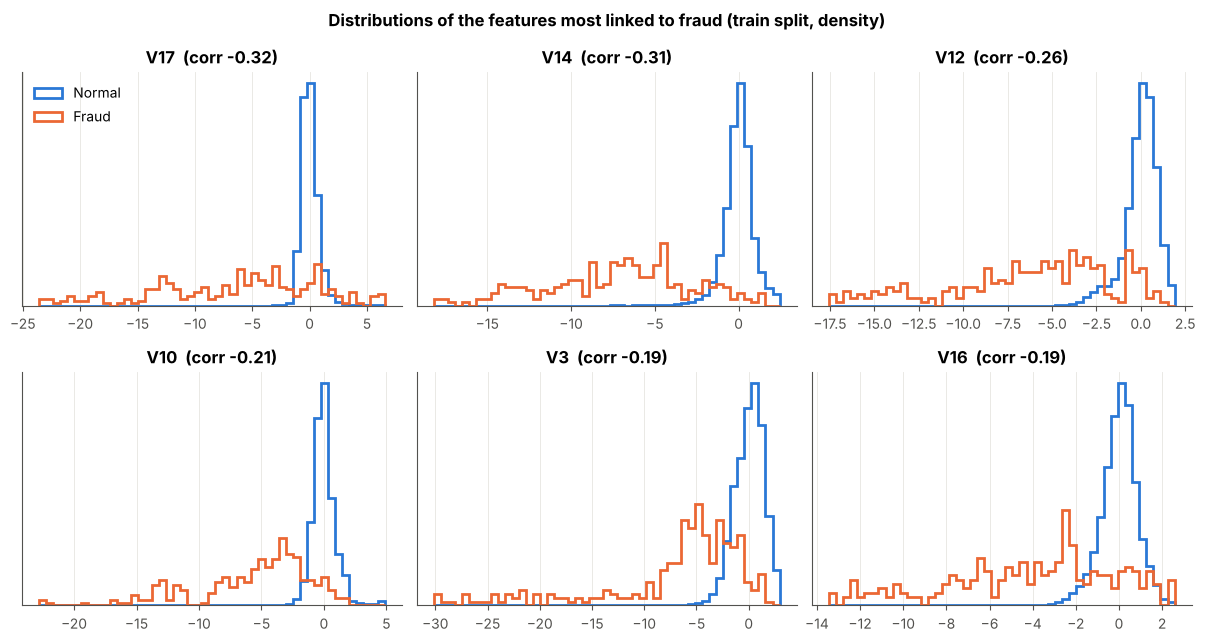

Label,median_Fraud,median_Normal
V17,-5.4637,-0.0646
V14,-6.7856,0.0507
V12,-5.4281,0.1390
V10,-4.5494,-0.0934
V3,-5.1223,0.1780
V16,-3.4392,0.0692


In [9]:
TOP_N = 6
top_features = corr_table.index[:TOP_N].tolist()
print('Top features by |correlation| with Class:', top_features)

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, feat in zip(axes.flat, top_features):
    values = eda[feat] if feat != 'Amount' else np.log1p(eda['Amount'])
    # Range from both classes' 0.5-99.5 percentiles, so the fraud tail is not cut off
    lo = min(values[eda['Class'] == c].quantile(0.005) for c in (0, 1))
    hi = max(values[eda['Class'] == c].quantile(0.995) for c in (0, 1))
    bins = np.linspace(lo, hi, 50)
    for c in (0, 1):
        ax.hist(values[eda['Class'] == c].clip(lo, hi), bins=bins, density=True,
                histtype='step', linewidth=2, color=CLASS_COLOURS[c], label=CLASS_NAMES[c])
    ax.set_title(f"{feat}  (corr {corr[feat]:+.2f})")
    ax.set_yticks([])
axes.flat[0].legend(loc='upper left')
fig.suptitle('Distributions of the features most linked to fraud (train split, density)',
             fontweight='bold')
fig.tight_layout()
save(fig, 'eda_top_features.png')
plt.show()

eda.groupby('Label')[top_features].median().T.rename(columns=lambda c: f'median_{c}')

## 7. Correlation heatmap

Saved figures/eda_heatmap.png


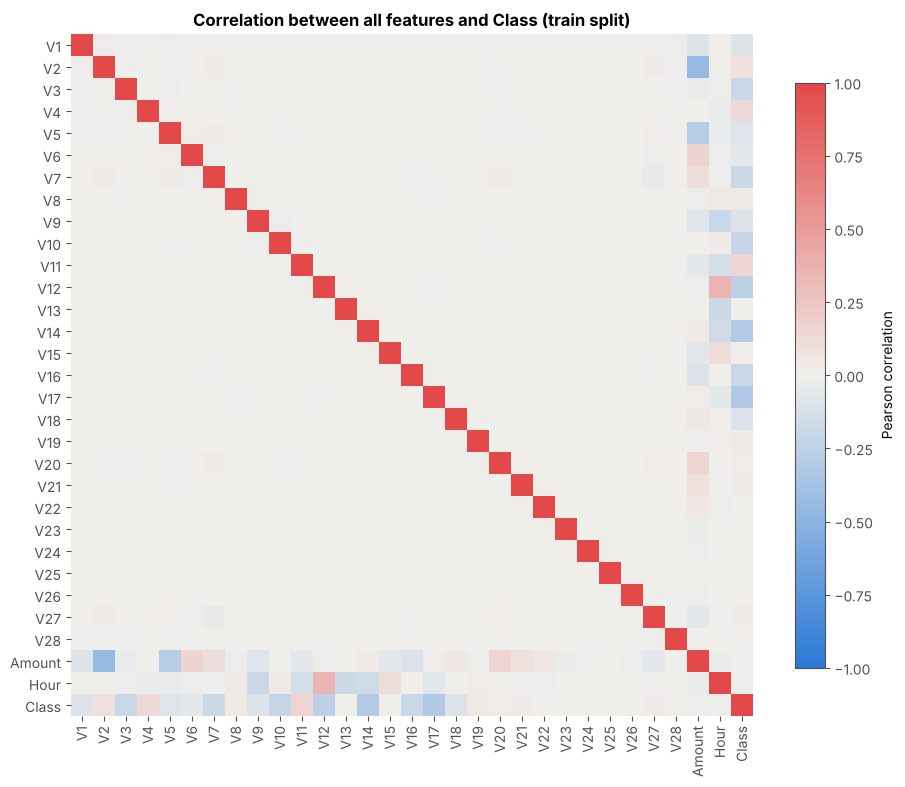

Largest |corr| between two V features: 0.0465
Median |corr| between two V features: 0.0023


,,corr,abs_corr
V2,Amount,-0.4484,0.4484
V12,Hour,0.3516,0.3516
V5,Amount,-0.2874,0.2874
V9,Hour,-0.1906,0.1906
V13,Hour,-0.1872,0.1872
V6,Amount,0.1636,0.1636
V14,Hour,-0.1636,0.1636
V20,Amount,0.1531,0.1531
V11,Hour,-0.1370,0.1370
V15,Hour,0.1113,0.1113


In [10]:
from matplotlib.colors import LinearSegmentedColormap

cmap = LinearSegmentedColormap.from_list('blue_grey_red', [NEG, MID, POS])
matrix = train[FEATURES + ['Class']].corr()

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(matrix)), matrix.columns, rotation=90)
ax.set_yticks(range(len(matrix)), matrix.index)
ax.grid(False)
for side in ('top', 'right', 'bottom', 'left'):
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson correlation')
ax.set_title('Correlation between all features and Class (train split)')
save(fig, 'eda_heatmap.png')
plt.show()

# Largest correlations between pairs of features (excluding Class)
feat_corr = train[FEATURES].corr()
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
         .stack().rename('corr').to_frame())
pairs['abs_corr'] = pairs['corr'].abs()
v_only = pairs[[a.startswith('V') and b.startswith('V') for a, b in pairs.index]]
print('Largest |corr| between two V features:', f"{v_only['abs_corr'].max():.4f}")
print('Median |corr| between two V features:', f"{v_only['abs_corr'].median():.4f}")
pairs.sort_values('abs_corr', ascending=False).head(10)

## Saved figures

In [11]:
sorted(p.name for p in FIG_DIR.glob('eda_*.png'))

['eda_amount_by_class.png',
 'eda_class_balance.png',
 'eda_corr_with_class.png',
 'eda_heatmap.png',
 'eda_hour_pattern.png',
 'eda_top_features.png']